# 4. Document AI — PDF 이해 / 계약서 / 영수증 / 표(Table) 분석

문서 이해 태스크는 텍스트 추출만으로는 놓치기 쉬운 **레이아웃 정보**가
핵심입니다. PDF는 페이지를 이미지로 렌더링해 VLM에 직접 입력합니다.

In [1]:
from vlm_utils import ask, ask_json, show

CONTRACT_PDF = "data/contract.pdf"
RECEIPT = "data/receipt.png"
TABLE = "data/table.png"

## PDF 이해
`pymupdf`(fitz)로 PDF 페이지를 이미지로 렌더링한 뒤 VLM에 전달합니다.

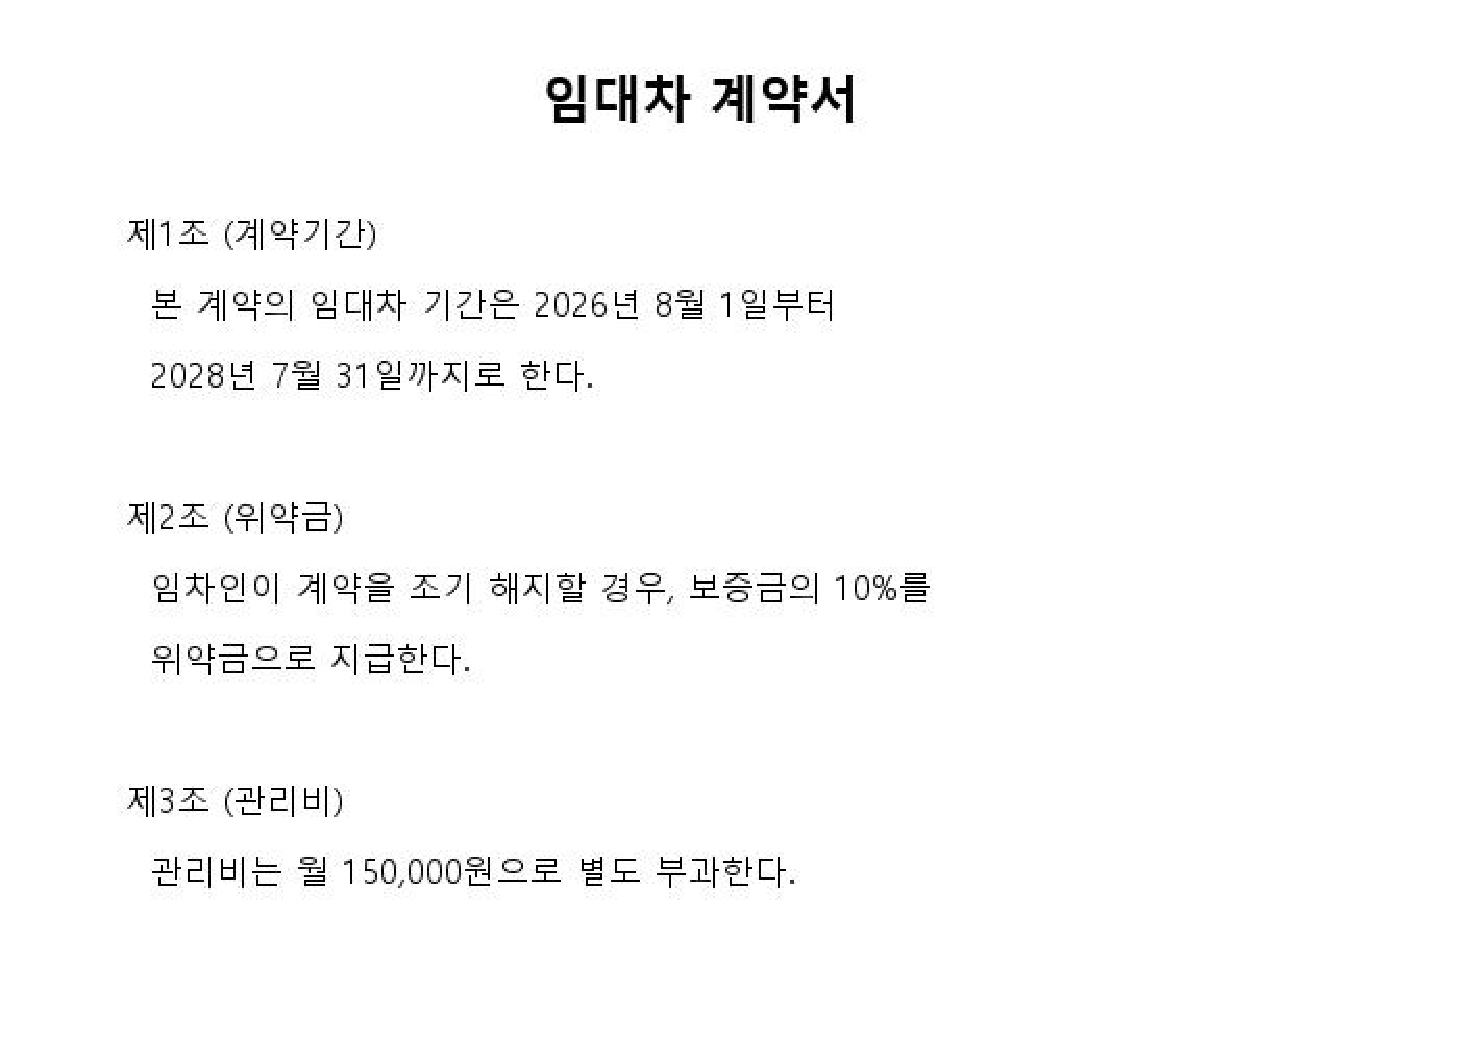

In [2]:
import fitz

doc = fitz.open(CONTRACT_PDF)
page = doc[0]
pix = page.get_pixmap(dpi=150)
contract_from_pdf = "data/_contract_page1.png"
pix.save(contract_from_pdf)
show(contract_from_pdf)

In [3]:
summary = ask(
    contract_from_pdf,
    "이 PDF 페이지의 핵심 내용을 3줄로 요약해줘.",
)
print(summary)

1. 임대차 계약 기간은 2026년 8월 1일부터 2028년 7월 31일까지로, 약속된 2년여의 단기 임대가 진행됩니다.  
2. 임차인이 계약을 조기 해지할 경우 보증금의 10%를 위약금으로 지급해야 하며, 이는 계약 이행 책임을 명확히 규명합니다.  
3. 관리비는 월 150,000원이 상한선이며, 임차인이 이 범위 내에서 부담할 수 있는 비용 조건을 정의하고 있습니다.


## 계약서 분석
정확도가 중요한 도메인이므로 **원문 문구를 그대로 인용**하도록 요청해
검증 가능한 답변을 받습니다.

In [4]:
contract_qa = ask(
    contract_from_pdf,
    "이 계약서 이미지에서 계약 기간과 위약금 조항을 찾아, 관련 원문 문장을 "
    "그대로 인용한 뒤 요약해줘. 해당 조항이 없으면 '명시되어 있지 않음'이라고 답해.",
)
print(contract_qa)

### 계약 기간 관련 원문  
**제1조 (계약기간)**  
본 계약의 임대차 기간은 2026년 8월 1일부터 2028년 7월 31일까지로 한다.  

### 위약금 조항 관련 원문  
**제2조 (위약금)**  
임차인이 계약을 조기 해지할 경우, 보증금의 10%를 위약금으로 지급한다.  

### 요약  
- **계약 기간**: 2026년 8월 1일 ~ 2028년 7월 31일  
- **위약금 조항**: 임차인의 계약 조기 해지 시 보증금의 10%를 위약금으로 지급함.  
(관리비 내용은 본 문제와 직접 관련 없음)


## 영수증 분석 — 구조화 추출
상호명, 날짜, 품목, 총액을 JSON 스키마로 한 번에 추출합니다.

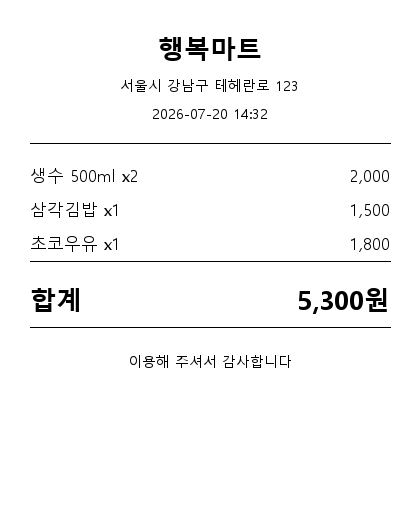

{'store': '행복마트', 'date': '2026-07-20', 'items': [{'name': '생수', 'qty': 2, 'price': 2000}, {'name': '삼각김밥', 'qty': 1, 'price': 1500}, {'name': '초코우유', 'qty': 1, 'price': 1800}], 'total': 5300}


In [5]:
show(RECEIPT)
receipt_schema = '''
아래 JSON 스키마로만 답해.
{
  "store": "string",
  "date": "YYYY-MM-DD",
  "items": [{"name": "string", "qty": "number", "price": "number"}],
  "total": "number"
}
'''
receipt_json = ask_json(RECEIPT, receipt_schema)
print(receipt_json)
assert receipt_json["total"] == 5300

## 표(Table) 분석
표는 "행-열 관계"가 핵심이므로, **마크다운 표 형식으로 그대로 옮겨 적게** 하면
구조가 잘 보존됐는지 눈으로 바로 확인할 수 있습니다.

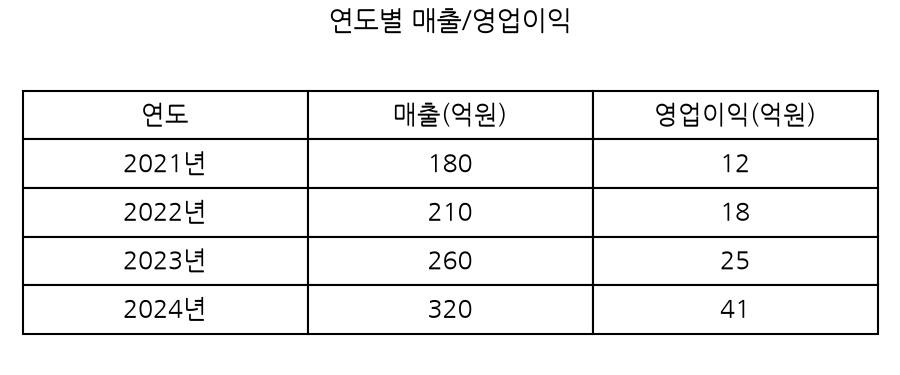

In [9]:
show(TABLE)

In [ ]:
table_qa = ask(TABLE, "이 표에서 '매출(억원)' 열의 값이 가장 큰 연도를 알려줘.")

print(table_qa)

이 표에서 '매출(억원)' 열의 값이 가장 큰 연도는 **2024년**입니다.  
- 2021년: 180 억원  
- 2022년: 210 억원  
- 2023년: 260 억원  
- 2024년: **320 억원**  

(2024년의 매출 값이 다른 연도들보다 가장 크기 때문)
